In [1]:
import pandas as pd

raw = pd.read_csv("sales.csv", dtype=str, keep_default_na=False)
print("Columns:", [repr(column) for column in raw.columns])
print(f"Rows: {len(raw)} | full duplicates in raw CSV: {int(raw.duplicated().sum())}")

for column in raw.columns:
    values = raw[column].str.strip()
    print(
        f"\n{column!r}: leading/trailing whitespace={(raw[column] != values).sum()}, "
        f"empty values={(values == '').sum()}"
    )
    if column.strip() in {"Region", "Product"}:
        display(values.value_counts(dropna=False).rename_axis("value").to_frame("count"))

for column in ["Quantity ", "Unit Price", "Discount"]:
    values = raw[column].str.strip()
    values = values[values != ""]
    invalid = values[pd.to_numeric(values, errors="coerce").isna()]
    print(f"\nUnparseable values in {column!r}:")
    display(invalid.value_counts().rename_axis("value").to_frame("count"))

dates = raw["Order Date"].str.strip()
dates = dates[dates != ""]
invalid_dates = dates[pd.to_datetime(dates, errors="coerce").isna()]
print("\nUnparseable values in 'Order Date':")
display(invalid_dates.value_counts().rename_axis("value").to_frame("count"))


Columns: ["'Order ID'", "'Region'", "'Product'", "'Quantity '", "'Unit Price'", "'Discount'", "'Order Date'"]
Rows: 1507 | full duplicates in raw CSV: 5

'Order ID': leading/trailing whitespace=0, empty values=0

'Region': leading/trailing whitespace=8, empty values=1


,count
value,
North,312
South,309
Central,296
West,293
East,285
south,3
west,2
EAST,2
north,1



'Product': leading/trailing whitespace=0, empty values=1


,count
value,
Keyboard,207
Headset,202
Printer paper,196
Notebook pack,189
Desk lamp,187
Monitor stand,183
Office chair,173
Mouse,168
Product,1



'Quantity ': leading/trailing whitespace=1, empty values=0

'Unit Price': leading/trailing whitespace=0, empty values=5

'Discount': leading/trailing whitespace=0, empty values=963

'Order Date': leading/trailing whitespace=0, empty values=1

Unparseable values in 'Quantity ':


,count
value,
1 762,1
1 745,1
Quantity,1
1 371,1
1 427,1


... (2 outputs left out)


Unparseable values in 'Discount':


,count
value,
Discount,1



Unparseable values in 'Order Date':


,count
value,
Order Date,1


In [2]:
sales = raw.copy()
raw_types = raw.dtypes.astype(str).rename("pandas dtype").to_frame()
print("Raw CSV column types:")
display(raw_types)

sales.columns = (
    sales.columns.str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
)
header_rows = sales.apply(
    lambda column: column.str.strip().str.lower().str.replace(
        r"\s+", "_", regex=True
    ).eq(column.name)
).all(axis=1)
print(f"Repeated header rows to remove: {int(header_rows.sum())}")
display(sales.loc[header_rows])
sales = sales.loc[~header_rows].copy()
print(f"Rows after removing the repeated header: {len(sales)}")

for column in ["region", "product"]:
    values = sales[column].str.strip().replace("", pd.NA)
    sales[column] = values.str.capitalize().astype("string")
sales["order_id"] = sales["order_id"].str.strip().astype("string")

conversion_issues = {}
quantity_text = sales["quantity"].str.strip().str.replace(r"\s+", "", regex=True)
parsed_quantity = pd.to_numeric(quantity_text.replace("", pd.NA), errors="coerce")
conversion_issues["quantity"] = int((quantity_text.ne("") & parsed_quantity.isna()).sum())
sales["quantity"] = parsed_quantity.astype("Int64")

unit_price_text = sales["unit_price"].str.strip().str.replace(",", ".", regex=False)
parsed_unit_price = pd.to_numeric(unit_price_text.replace("", pd.NA), errors="coerce")
conversion_issues["unit_price"] = int((unit_price_text.ne("") & parsed_unit_price.isna()).sum())
sales["unit_price"] = parsed_unit_price.astype("Float64")

discount_text = sales["discount"].astype("string").str.strip()
discount_text = discount_text.replace({"<NA>": pd.NA, "": pd.NA})
parsed_discount = pd.to_numeric(discount_text, errors="coerce")
conversion_issues["discount"] = int((discount_text.notna() & parsed_discount.isna()).sum())
sales["discount"] = parsed_discount.astype("Float64")

order_date_text = sales["order_date"].astype("string").str.strip().replace("", pd.NA)
parsed_dates = pd.to_datetime(order_date_text, errors="coerce")
conversion_issues["order_date"] = int((order_date_text.notna() & parsed_dates.isna()).sum())
sales["order_date"] = parsed_dates

print("Non-empty unparseable values after normalization:")
display(pd.Series(conversion_issues, name="unparseable value count").to_frame())

semantic_types = {
    "order_id": "text identifier",
    "region": "text category",
    "product": "text category",
    "quantity": "integer",
    "unit_price": "decimal amount",
    "discount": "decimal amount; missing values allowed",
    "order_date": "date",
}
column_types = pd.DataFrame(
    {
        "column": sales.columns,
        "pandas dtype after cleaning": [str(sales[column].dtype) for column in sales.columns],
        "semantic type": [semantic_types[column] for column in sales.columns],
    }
)
print("Column types after cleaning:")
display(column_types)
display(sales.head())


Raw CSV column types:


,pandas dtype
Order ID,str
Region,str
Product,str
Quantity,str
Unit Price,str
Discount,str
Order Date,str


Repeated header rows to remove: 1


,order_id,region,product,quantity,unit_price,discount,order_date
751,Order ID,Region,Product,Quantity,Unit Price,Discount,Order Date


Rows after removing the repeated header: 1506
Non-empty unparseable values after normalization:


,unparseable value count
quantity,0
unit_price,0
discount,0
order_date,0


Column types after cleaning:


,column,pandas dtype after cleaning,semantic type
0,order_id,string,text identifier
1,region,string,text category
2,product,string,text category
3,quantity,Int64,integer
4,unit_price,Float64,decimal amount
5,discount,Float64,decimal amount; missing values allowed
6,order_date,datetime64[us],date


,order_id,region,product,quantity,unit_price,discount,order_date
0,SO-10001,South,Office chair,32,249.0,398.4,2026-08-07
1,SO-10002,East,Monitor stand,1,59.0,<NA>,2026-02-19
2,SO-10003,South,Headset,14,119.0,<NA>,2026-03-25
3,SO-10004,East,Mouse,11,29.5,<NA>,2026-07-25
4,SO-10005,South,Printer paper,6,21.0,12.6,2026-03-24


In [3]:
from decimal import Decimal

total_rows = sales["order_id"].str.strip().str.upper().eq("TOTAL")
if int(total_rows.sum()) != 1:
    raise ValueError(f"Expected exactly one TOTAL row, found: {int(total_rows.sum())}")

total_row = sales.loc[total_rows].iloc[0]
items = sales.loc[~total_rows].copy()
total_quantity = int(total_row["quantity"])
quantity_sum = int(items["quantity"].sum())
total_discount = Decimal(str(total_row["discount"]))
discount_sum = sum(
    (Decimal(str(value)) for value in items["discount"].dropna()),
    Decimal("0"),
)
priced_items = items.dropna(subset=["quantity", "unit_price"])
gross_total = sum(
    (
        Decimal(str(quantity)) * Decimal(str(unit_price))
        for quantity, unit_price in zip(priced_items["quantity"], priced_items["unit_price"])
    ),
    Decimal("0"),
)

display(pd.DataFrame([
    {
        "check": "Quantity",
        "value in TOTAL": total_quantity,
        "sum across rows": quantity_sum,
        "matches": total_quantity == quantity_sum,
    },
    {
        "check": "Discount",
        "value in TOTAL": total_discount,
        "sum across rows": discount_sum,
        "matches": total_discount == discount_sum,
    },
]))
print(f"Sum of Quantity * Unit Price for rows with a price: {gross_total:.2f}")
print(f"Rows missing Unit Price: {int(items['unit_price'].isna().sum())}")

duplicate_rows = items.loc[items.duplicated(keep=False)].sort_values("order_id")
print(f"Rows belonging to full duplicates: {len(duplicate_rows)}")
display(duplicate_rows)
duplicate_id_mask = items["order_id"].duplicated(keep=False)
duplicate_ids = items.loc[duplicate_id_mask, "order_id"].drop_duplicates().tolist()
print(f"Rows with repeated order_id: {int(duplicate_id_mask.sum())}")
print(f"Repeated order_id values: {duplicate_ids}")

duplicate_count = int(items.duplicated().sum())
sales = items.drop_duplicates().copy()
print("TOTAL row removed: 1")
print(f"Full duplicates removed: {duplicate_count}")
print(f"Rows in the cleaned dataset: {len(sales)}")


,check,value in TOTAL,sum across rows,matches
0,Quantity,37150,37150,True
1,Discount,65924.67,65924.67,True


Sum of Quantity * Unit Price for rows with a price: 2636947.10
Rows missing Unit Price: 4
Rows belonging to full duplicates: 10


,order_id,region,product,quantity,unit_price,discount,order_date
304,SO-10305,South,Notebook pack,34,12.5,<NA>,2026-05-19
305,SO-10305,South,Notebook pack,34,12.5,<NA>,2026-05-19
823,SO-10822,West,Monitor stand,4,59.0,<NA>,2026-06-24
824,SO-10822,West,Monitor stand,4,59.0,<NA>,2026-06-24
968,SO-10966,Central,Headset,11,119.0,130.9,2026-07-30
969,SO-10966,Central,Headset,11,119.0,130.9,2026-07-30
1243,SO-11240,West,Headset,20,119.0,<NA>,2026-07-08
1244,SO-11240,West,Headset,20,119.0,<NA>,2026-07-08
1409,SO-11405,North,Desk lamp,27,39.9,<NA>,2026-09-05
1410,SO-11405,North,Desk lamp,27,39.9,<NA>,2026-09-05


Rows with repeated order_id: 10
Repeated order_id values: ['SO-10305', 'SO-10822', 'SO-10966', 'SO-11240', 'SO-11405']
TOTAL row removed: 1
Full duplicates removed: 5
Rows in the cleaned dataset: 1500


Summary of all columns:


,dtype,missing,unique_values
order_id,string,0,1500
region,string,0,5
product,string,0,8
quantity,Int64,0,48
unit_price,Float64,4,9
discount,Float64,959,291
order_date,datetime64[us],0,267


order_id: 1500 unique values, 0 repeated rows

Value distribution for region:


,count
value,
North,312
South,311
Central,296
West,293
East,288



Value distribution for product:


,count
value,
Keyboard,207
Headset,200
Printer paper,196
Notebook pack,188
Desk lamp,186
Monitor stand,182
Office chair,173
Mouse,168


... (2 outputs left out)

unit_price distribution by product:


,product,unit_price,row_count
0,Desk lamp,39.9,186
1,Headset,119.0,200
2,Keyboard,89.0,205
3,Keyboard,<NA>,2
4,Monitor stand,59.0,182
5,Mouse,29.5,168
6,Notebook pack,12.5,188
7,Office chair,249.0,173
8,Printer paper,21.0,194
9,Printer paper,<NA>,2


Rows missing unit_price before imputation:


,order_id,region,product,quantity,unit_price,discount,order_date
610,SO-10610,North,Printer paper,40,<NA>,<NA>,2026-09-04
1102,SO-11099,North,Printer paper,10,<NA>,<NA>,2026-05-08
1354,SO-11350,North,Keyboard,2,<NA>,<NA>,2026-01-20
1482,SO-11477,South,Keyboard,37,<NA>,164.65,2026-02-25


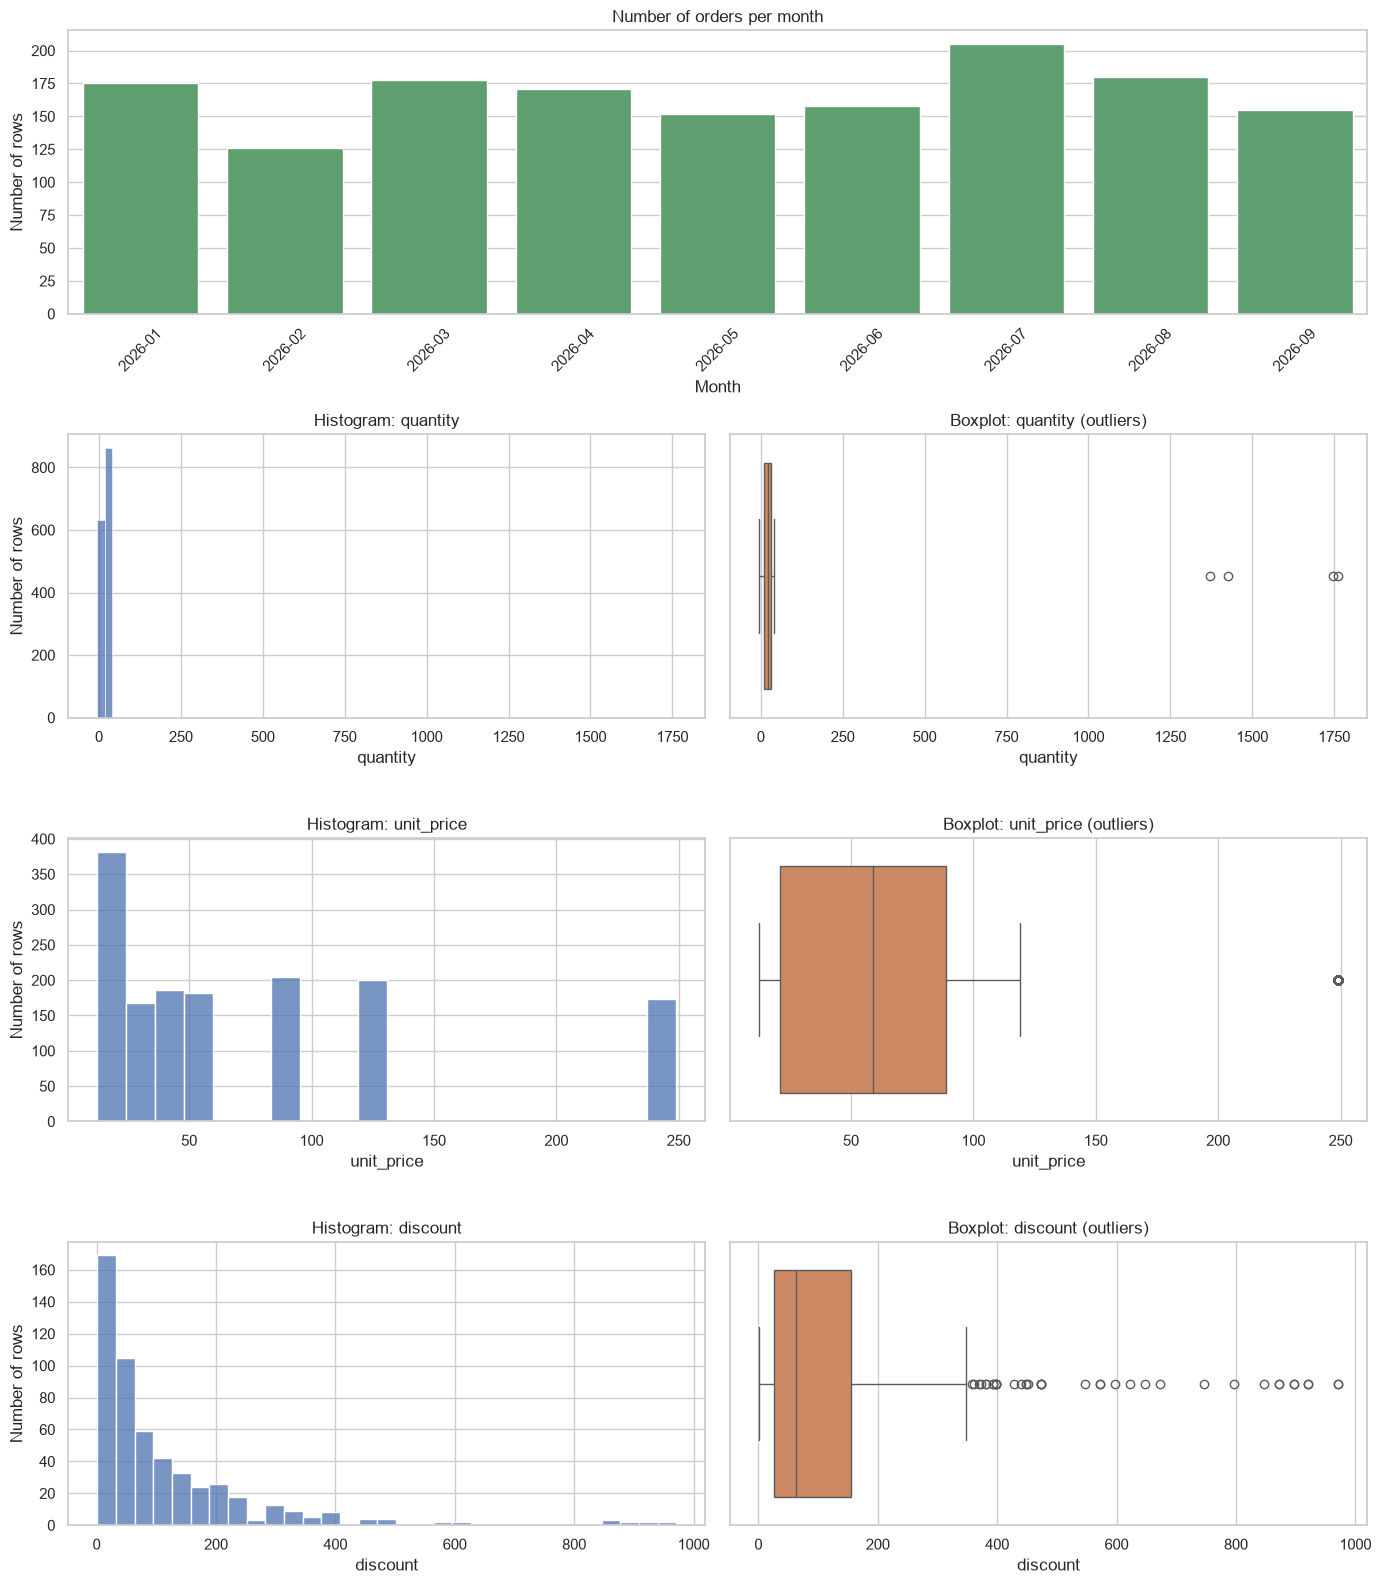

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

column_summary = pd.DataFrame(
    {
        "dtype": sales.dtypes.astype(str),
        "missing": sales.isna().sum(),
        "unique_values": sales.nunique(dropna=False),
    }
)
print("Summary of all columns:")
display(column_summary)
print(
    f"order_id: {sales['order_id'].nunique(dropna=False)} unique values, "
    f"{int(sales['order_id'].duplicated().sum())} repeated rows"
)

for column in ["region", "product"]:
    counts = sales[column].value_counts(dropna=False)
    print(f"\nValue distribution for {column}:")
    display(counts.rename_axis("value").to_frame("count"))

quantity_over_1000 = sales.loc[sales["quantity"].gt(1000)].copy()
quantity_over_1000["total_price"] = (
    quantity_over_1000["quantity"] * quantity_over_1000["unit_price"]
)
print("Rows with quantity above 1000:")
display(
    quantity_over_1000[
        ["order_id", "region", "product", "quantity", "unit_price", "discount", "order_date", "total_price"]
    ].sort_values("quantity", ascending=False)
)

unit_price_by_product = (
    sales.groupby(["product", "unit_price"], dropna=False)
    .size()
    .rename("row_count")
    .reset_index()
    .sort_values(["product", "unit_price"], na_position="last")
)
print("unit_price distribution by product:")
display(unit_price_by_product)
missing_unit_price = sales.loc[sales["unit_price"].isna()]
print("Rows missing unit_price before imputation:")
display(missing_unit_price)

monthly_orders = (
    sales.dropna(subset=["order_date"])
    .assign(order_month=lambda frame: frame["order_date"].dt.to_period("M").astype(str))
    .groupby("order_month")
    .size()
    .rename("orders")
    .reset_index()
)

sns.set_theme(style="whitegrid", palette="deep")
fig = plt.figure(figsize=(14, 16))
grid = fig.add_gridspec(4, 2)
monthly_ax = fig.add_subplot(grid[0, :])
sns.barplot(data=monthly_orders, x="order_month", y="orders", color="#55A868", ax=monthly_ax)
monthly_ax.set_title("Number of orders per month")
monthly_ax.set_xlabel("Month")
monthly_ax.set_ylabel("Number of rows")
monthly_ax.tick_params(axis="x", rotation=45)

for row, column in enumerate(["quantity", "unit_price", "discount"], start=1):
    values = sales[column].dropna().astype("float64")
    histogram_ax = fig.add_subplot(grid[row, 0])
    boxplot_ax = fig.add_subplot(grid[row, 1])
    sns.histplot(x=values, bins="auto", color="#4C72B0", ax=histogram_ax)
    histogram_ax.set_title(f"Histogram: {column}")
    histogram_ax.set_xlabel(column)
    histogram_ax.set_ylabel("Number of rows")
    sns.boxplot(x=values, color="#DD8452", ax=boxplot_ax)
    boxplot_ax.set_title(f"Boxplot: {column} (outliers)")
    boxplot_ax.set_xlabel(column)

fig.tight_layout()
plt.show()


In [5]:
missing_price = sales["unit_price"].isna()
product_price_counts = sales.groupby("product")["unit_price"].nunique(dropna=True)
if product_price_counts.gt(1).any():
    raise ValueError("unit_price is not constant within every product.")

product_medians = sales.groupby("product")["unit_price"].transform("median")
if product_medians.loc[missing_price].isna().any():
    raise ValueError("Cannot calculate a product-specific median for a product.")

sales.loc[missing_price, "unit_price"] = product_medians.loc[missing_price]
print(f"Imputed unit_price values: {int(missing_price.sum())}")
display(sales.loc[missing_price, ["order_id", "product", "unit_price"]])


Imputed unit_price values: 4


,order_id,product,unit_price
610,SO-10610,Printer paper,21.0
1102,SO-11099,Printer paper,21.0
1354,SO-11350,Keyboard,89.0
1482,SO-11477,Keyboard,89.0
